# Inferring the interaction network when one species is barely measured (or not measured at all)

This notebook uses `hs_pinn.py`, which reuses the simulation helpers and the training curriculum of `PINN-Inference.ipynb`
(data-only warm-up → least-squares reset of $(r, A)$ → physics-weight ramp → refinement) with these changes:

1. **Masked data loss**: a species can have only a few data points, or none. The physics loss is still applied to *all* species, so the network has to produce a trajectory for the unmeasured species that is consistent with the gLV equations and with what the measured species do.
2. **Positive outputs and log-form residual**: $x = \exp(\text{net})$ and the residual is $\frac{d \ln x_i}{dt} - (r_i + \sum_j A_{ij} x_j)$. Without this, the unmeasured species can collapse to $x = 0$, which satisfies the standard residual trivially.
3. **L-BFGS polish** (double precision) after Adam. This is what makes the partially observed problem work: Adam alone stops far from the solution.
4. Entries of $r$ and $A$ can be **frozen** (e.g. known growth rates).
5. The per-IC PINNs are evaluated as one batched network with analytic time derivatives (same architecture, faster on CPU).

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import hs_pinn as hs
from showcase import plot_trajectories, plot_matrices

torch.set_num_threads(4)
np.set_printoptions(precision=3, suppress=True)

# Example 1: one species measured at only 3 time points

Five species, ten initial conditions, simulated exactly as in `PINN-Inference.ipynb`. The species with the strongest effect on the others is measured at 3 time points per trajectory (start, middle, end); the other four are measured at all 101 points. Gaussian noise with std 0.01 is added to every measurement.

In [2]:
n_species, RSEED, noise_std, n_pts = 5, 18, 0.01, 3

com = hs.make_community(n_species, seed=RSEED)          # r, A, initial conditions, time grid and clean trajectories
sparse = hs.most_influential_species(com)               # index of the species that will be barely measured
print(f"Sparse species: sp{sparse + 1}")
print(f"Growth rates:\n{com['r']}\nInteraction matrix:\n{com['A']}")

Sparse species: sp4
Growth rates:
[1.064 2.752 0.892 1.128 1.354]
Interaction matrix:
[[-1.     0.504  0.    -0.168 -0.323]
 [ 0.    -1.     0.    -0.551  0.   ]
 [ 0.     0.    -1.     1.034  0.   ]
 [ 0.301 -0.282  0.    -1.     0.442]
 [-0.267  0.     0.115  0.447 -1.   ]]


In [3]:
res = hs.train(com, hidden=sparse, n_hidden_pts=n_pts, noise_std=noise_std, lbfgs_iters=3000, log_every=1000)

  ep      0  data 1.20e+01  phys 9.26e+00  w 0.00e+00  A_err 1.390


  ep   1000  data 2.20e-03  phys 4.21e+01  w 0.00e+00  A_err 1.390


  ep   2000  data 1.04e-03  phys 1.76e-02  w 7.54e-04  A_err 0.431


  ep   3000  data 8.91e-04  phys 1.35e-02  w 7.54e-03  A_err 0.408


  ep   4000  data 8.56e-04  phys 3.83e-03  w 7.54e-02  A_err 0.239


  ep   5000  data 9.31e-04  phys 5.83e-04  w 7.54e-01  A_err 0.123


  ep   5999  data 9.16e-04  phys 3.85e-04  w 7.54e-01  A_err 0.106


  after L-BFGS: A_err 0.025


The model never sees the gray curve below, only the three black points. The red curve is the PINN output for that species, which is determined by the physics loss.

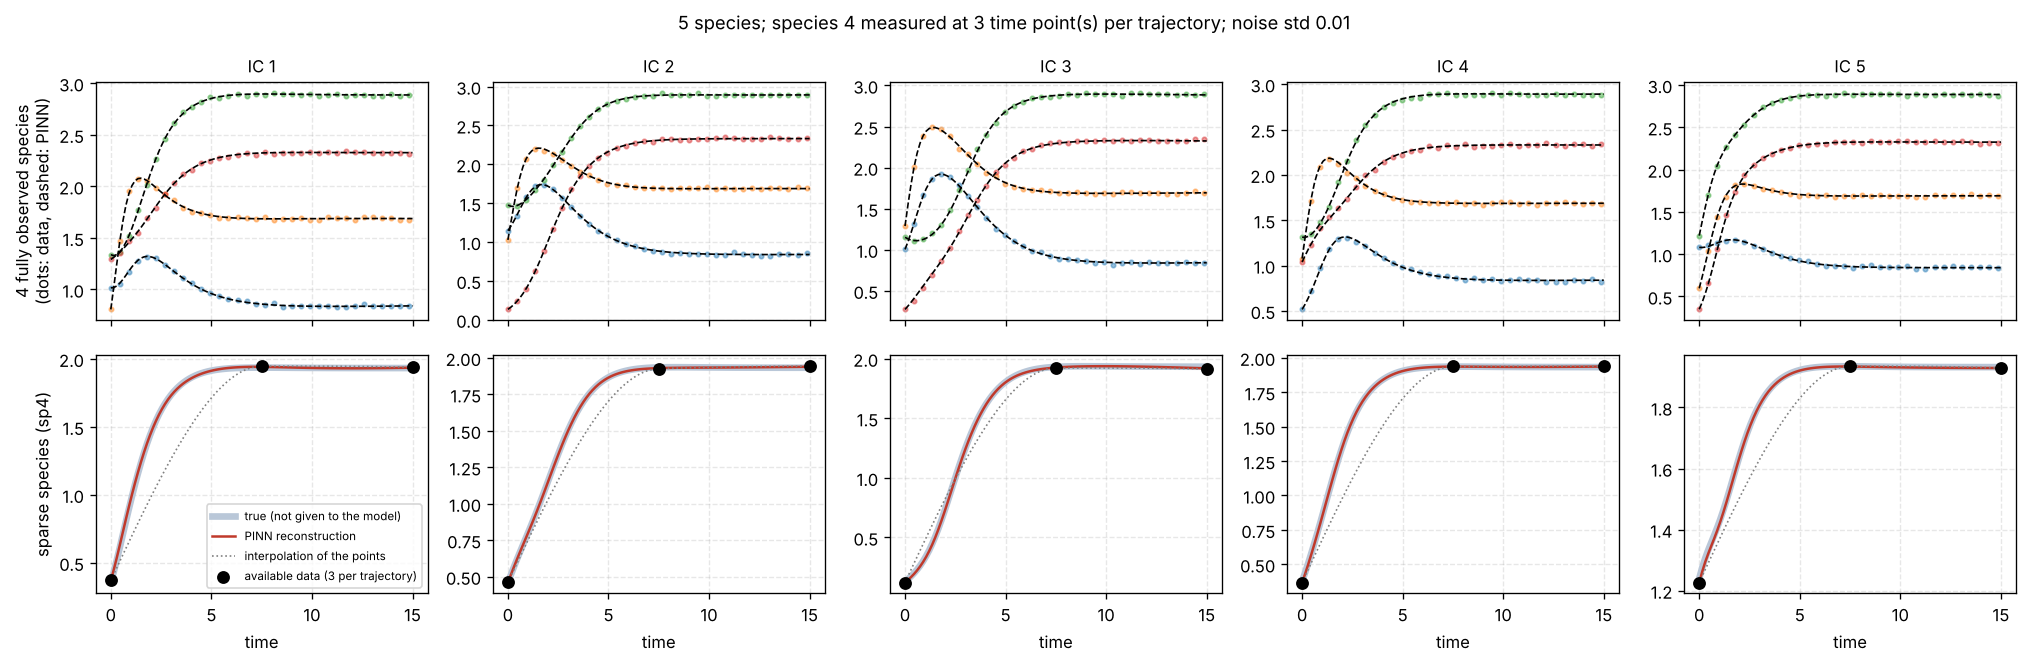

In [4]:
plot_trajectories(com, res, dpi=120); plt.show()

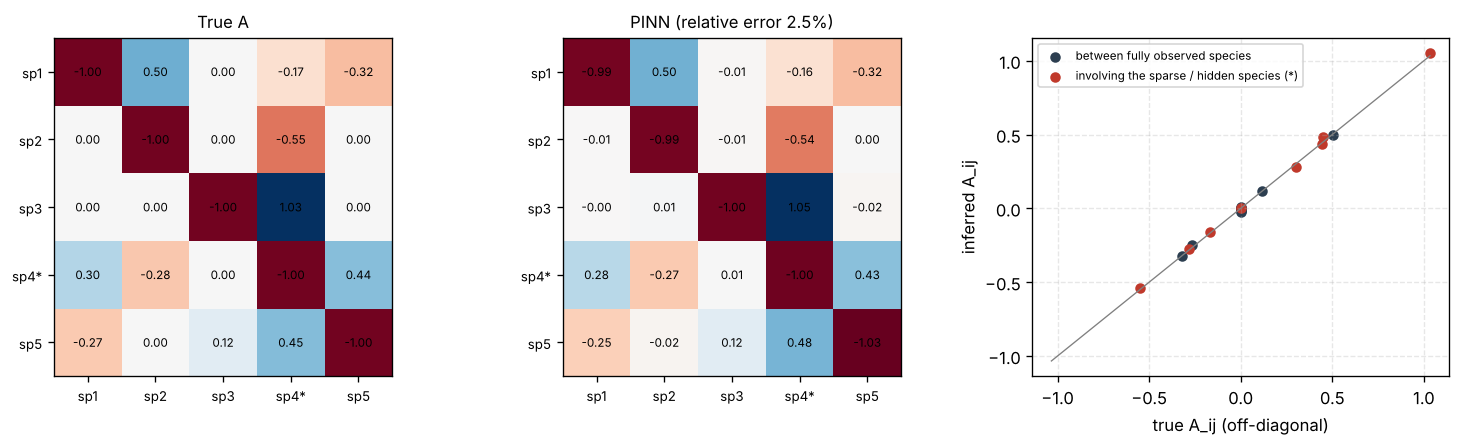

In [5]:
plot_matrices(com, res, dpi=120); plt.show()

Comparison with what gradient matching can do with the same data: (a) interpolate the three points and regress, (b) leave the species out of the model. Both baselines get smoothing-spline derivatives that use the true noise level. Errors are relative Frobenius errors in %.

In [6]:
m = res['metrics']
b_int = hs.baseline_interpolate_hidden(com, sparse, n_pts, noise_std)
b_ign = hs.baseline_ignore_hidden(com, sparse, noise_std)
rows = {
    'PINN (3 points for the sparse species)': [m['A_err'], m['A_obs_block_err'], m['A_hidden_col_err'], m['A_hidden_row_err'], m['sign_acc']],
    'Gradient matching, 3 points interpolated': [b_int['A_err'], b_int['A_obs_block_err'], b_int['A_hidden_col_err'], b_int['A_hidden_row_err'], b_int['sign_acc']],
    'Gradient matching, species left out': [np.nan, b_ign['A_obs_block_err'], np.nan, np.nan, np.nan],
}
table = pd.DataFrame(rows, index=['A (all)', 'A between fully observed species', 'effect of sparse species on others',
                                  'effect of others on sparse species', 'sign accuracy']).T
table.iloc[:, :4] = (100 * table.iloc[:, :4]).round(1)
table

,A (all),A between fully observed species,effect of sparse species on others,effect of others on sparse species,sign accuracy
PINN (3 points for the sparse species),2.5,2.4,3.3,3.6,1.000000
"Gradient matching, 3 points interpolated",51.0,26.2,63.2,149.1,0.818182
"Gradient matching, species left out",NaN,36.0,NaN,NaN,NaN


# Example 2: one species with no data at all, growth rates known

Four species; the most influential one is never measured. The growth rates $r$ are given (not trained). The abundance scale of a species that is never measured cannot be identified (multiplying $x_h$ by $c$ and dividing its column of $A$ by $c$ gives the same observations), so its self-regulation is frozen at $A_{hh} = -1$, which is the value used by the generator.

**How to tell whether a run can be trusted:** `sim_fit_rmse` integrates the inferred model from the inferred initial state and compares it with the available data. It only uses the data, so it also works on real experiments. A good run has `sim_fit_rmse` close to the noise level; a clearly larger value means the run ended in a wrong solution and should be restarted with another seed (`hs.train_with_restarts` does this automatically).

In [7]:
n_species, RSEED, noise_std = 4, 4, 0.01

com2 = hs.make_community(n_species, seed=RSEED)
hidden = hs.most_influential_species(com2)
res2 = hs.train(com2, hidden=hidden, n_hidden_pts=0, r_known=True, noise_std=noise_std, lbfgs_iters=3000, log_every=1000)
m2 = res2['metrics']
print(f"\nsim_fit_rmse = {m2['sim_fit_rmse']:.4f}   (noise std = {noise_std})")
print(f"Relative error on A: {100 * m2['A_err']:.1f}%   |   on the hidden species' trajectory: {100 * m2['x_hidden_err']:.1f}%   |   sign accuracy: {m2['sign_acc']:.2f}")

  ep      0  data 7.15e+00  phys 4.21e+00  w 0.00e+00  A_err 1.130


  ep   1000  data 1.32e-03  phys 1.69e+01  w 0.00e+00  A_err 1.130


  ep   2000  data 8.15e-04  phys 1.25e-01  w 2.45e-04  A_err 0.473


  ep   3000  data 6.74e-04  phys 5.79e-03  w 2.45e-03  A_err 0.143


  ep   4000  data 6.03e-04  phys 2.30e-03  w 2.45e-02  A_err 0.105


  ep   5000  data 5.86e-04  phys 5.77e-04  w 2.45e-01  A_err 0.082


  ep   5999  data 5.79e-04  phys 3.79e-04  w 2.45e-01  A_err 0.074


  after L-BFGS: A_err 0.045



sim_fit_rmse = 0.0100   (noise std = 0.01)
Relative error on A: 4.5%   |   on the hidden species' trajectory: 5.9%   |   sign accuracy: 1.00


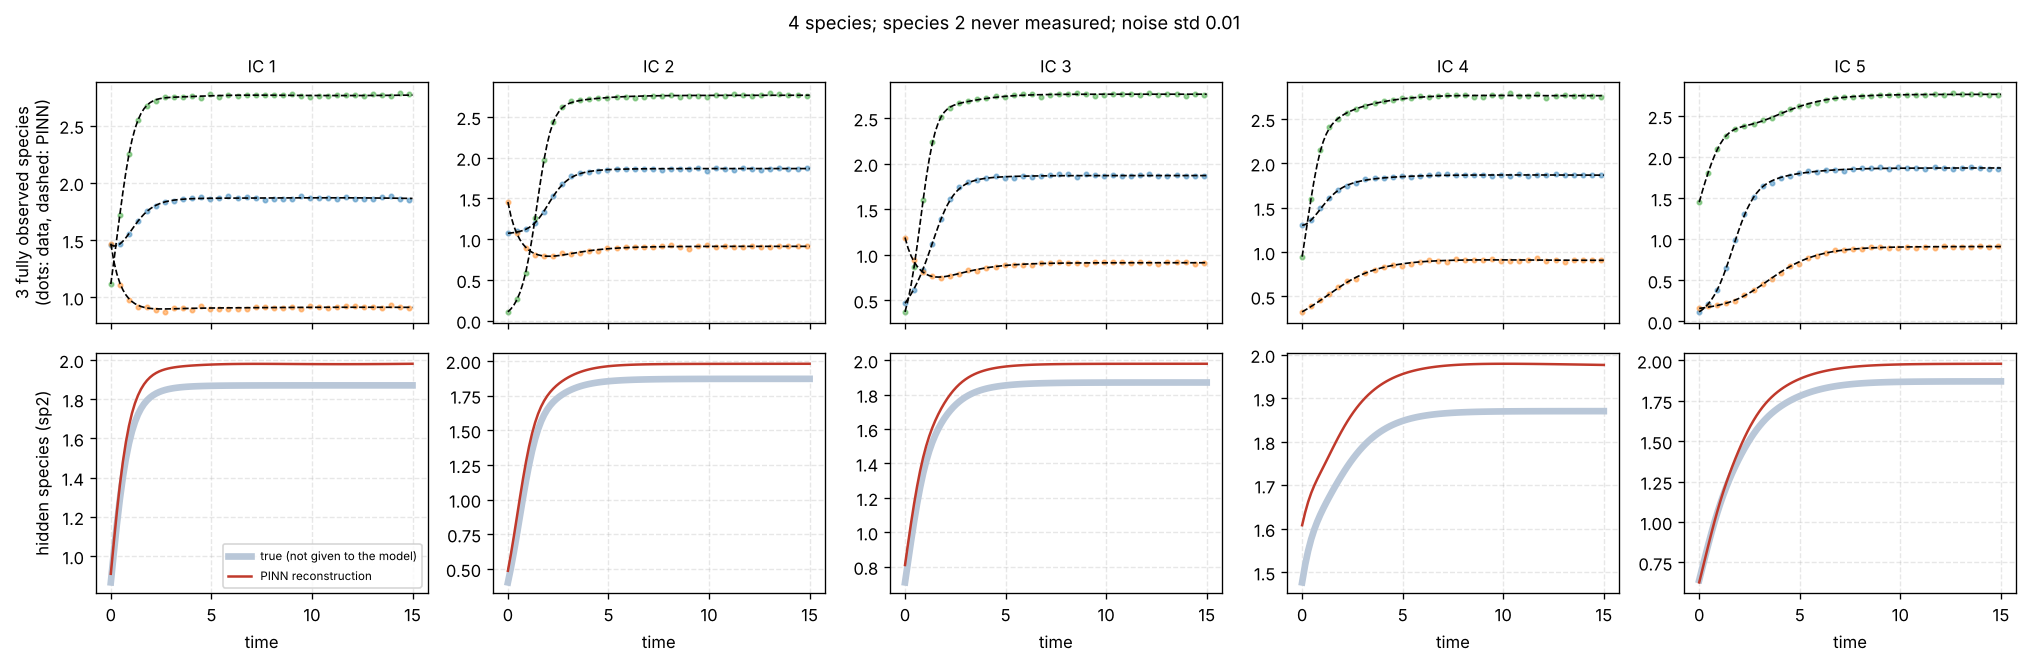

In [8]:
plot_trajectories(com2, res2, dpi=120); plt.show()

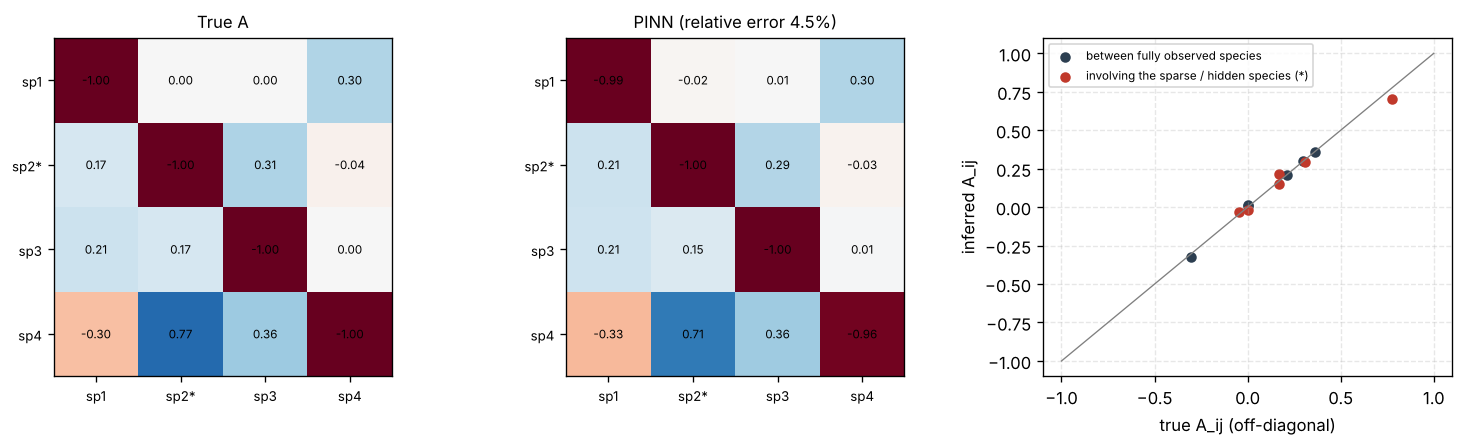

In [9]:
plot_matrices(com2, res2, dpi=120); plt.show()